In [35]:
%pip install -q matplotlib tensorflow numpy tensorflow-probability


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Module 7 Assignment - Improved Digit Generation with VAEs

> Submitted by Phillip Amir Esguerra

> SOURCE MODIFIED: Using keras package directly as I'm using tf 2.19

In [54]:
import tensorflow as tf
import keras
from keras.layers import Input, Dense, Lambda, Flatten, Reshape, Layer
from keras.models import Model
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_probability as tfp

# Load and preprocess MNIST data
(x_train, y_train), (_, _) = keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.
x_train = x_train.reshape((len(x_train), 28, 28, 1))

class Sampling(Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon
    
def build_encoder(input_shape, intermediate_dim, latent_dim):
    encoder_inputs = Input(shape=input_shape)
    x = Flatten()(encoder_inputs)
    x = Dense(intermediate_dim, activation='relu')(x)
    z_mean = Dense(latent_dim, name='z_mean')(x)
    z_log_var = Dense(latent_dim, name='z_log_var')(x)
    z = Sampling()([z_mean, z_log_var])
    encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name='encoder')
    return encoder

def build_decoder(latent_dim, intermediate_dim):
    decoder_inputs = Input(shape=(latent_dim,))
    x = Dense(intermediate_dim, activation='relu')(decoder_inputs)
    x = Dense(784, activation='sigmoid')(x)
    decoder_outputs = Reshape((28, 28, 1))(x)
    decoder = Model(decoder_inputs, decoder_outputs, name='decoder')
    return decoder

class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name='total_loss')
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(name='reconstruction_loss')
        self.kl_loss_tracker = tf.keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            # Encoder output
            z_mean, z_log_var, z = self.encoder(data)
            # Reconstruction
            reconstruction = self.decoder(z)

            # Flatten input and reconstruction for binary crossentropy
            flat_data = tf.reshape(data, (-1, 784))
            flat_reconstruction = tf.reshape(reconstruction, (-1, 784))

            # Reconstruction loss (fixed axis handling)
            reconstruction_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(
                    flat_data,
                    flat_reconstruction
                )
            ) * 784

            # KL divergence loss
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                    axis=1
                )
            )

            # Total loss
            total_loss = reconstruction_loss + kl_loss

        # Compute gradients
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        # Update metrics
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstruction = self.decoder(z)
        return reconstruction

def generate_digits(decoder, latent_dim, n=10):
    """Generate n new digits using the decoder"""
    z_sample = np.random.normal(size=(n, latent_dim))
    x_decoded = decoder.predict(z_sample)
    return x_decoded


In [57]:
def plot_digits(epochs, digits):
    plt.figure(figsize=(10, 2))
    for i in range(10):
        plt.subplot(1, 10, i + 1)
        plt.imshow(digits[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
    plt.tight_layout()
    plt.title(f'Generated Digits after {epochs} Epochs')
    plt.show()

In [38]:
# Network parameters
input_shape = (28, 28, 1)
batch_size = 128
latent_dim = 2
intermediate_dim = 512
epochs = 5

In [39]:
results = []
for epochs in [5, 15, 30, 50, 100]:
    encoder = build_encoder(input_shape, intermediate_dim, latent_dim)
    decoder = build_decoder(latent_dim, intermediate_dim)

    # Create and compile VAE
    print(f"Creating VAE model for {epochs} epochs...")
    vae = VAE(encoder, decoder)
    vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4))

    # Train VAE
    print(f"Training VAE for {epochs} epochs...")
    vae.fit(x_train,
            epochs=epochs,
            batch_size=batch_size,
            shuffle=True)

    # After training the VAE, you can use it like this:
    print("\nGenerating new digits...")
    new_digits = generate_digits(decoder, latent_dim, 10)  # Generates 10 new digits
    results.append({
            "epochs": epochs,
            "digits": new_digits,
            "encoder": encoder,
            "decoder": decoder
        })

Creating VAE model for 5 epochs...
Training VAE for 5 epochs...
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - kl_loss: 22.4538 - loss: 375.6288 - reconstruction_loss: 353.1750
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 12.5192 - loss: 208.0317 - reconstruction_loss: 195.5125
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 8.2263 - loss: 194.5158 - reconstruction_loss: 186.2895
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 6.6374 - loss: 190.3007 - reconstruction_loss: 183.6633
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - kl_loss: 5.9149 - loss: 187.6488 - reconstruction_loss: 181.7340

Generating new digits...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Creating VAE model for 15 epochs...
Training VAE for 15 epochs...
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 26.3948 - loss: 369.2600 - reconstruction_loss: 342.8652
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 13.0558 - loss: 208.8285 - reco

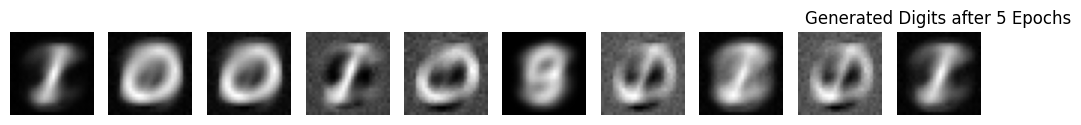

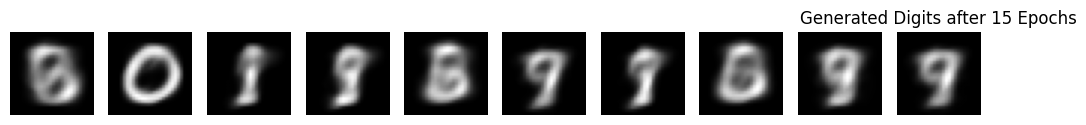

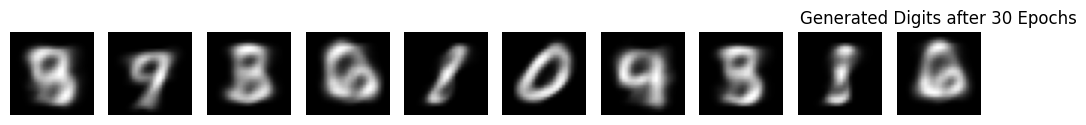

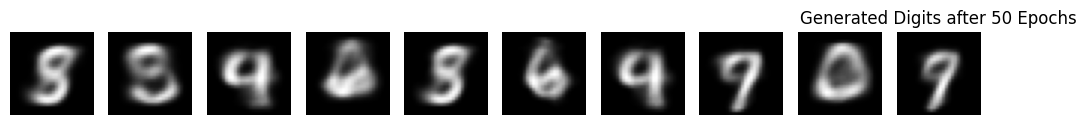

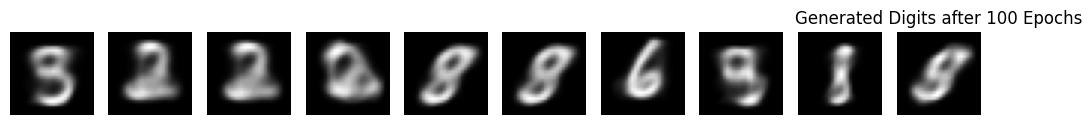

In [40]:
# To visualize the generated digits
for result in results:
    plot_digits(result["epochs"], result["digits"])

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 482us/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 473us/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 469us/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step


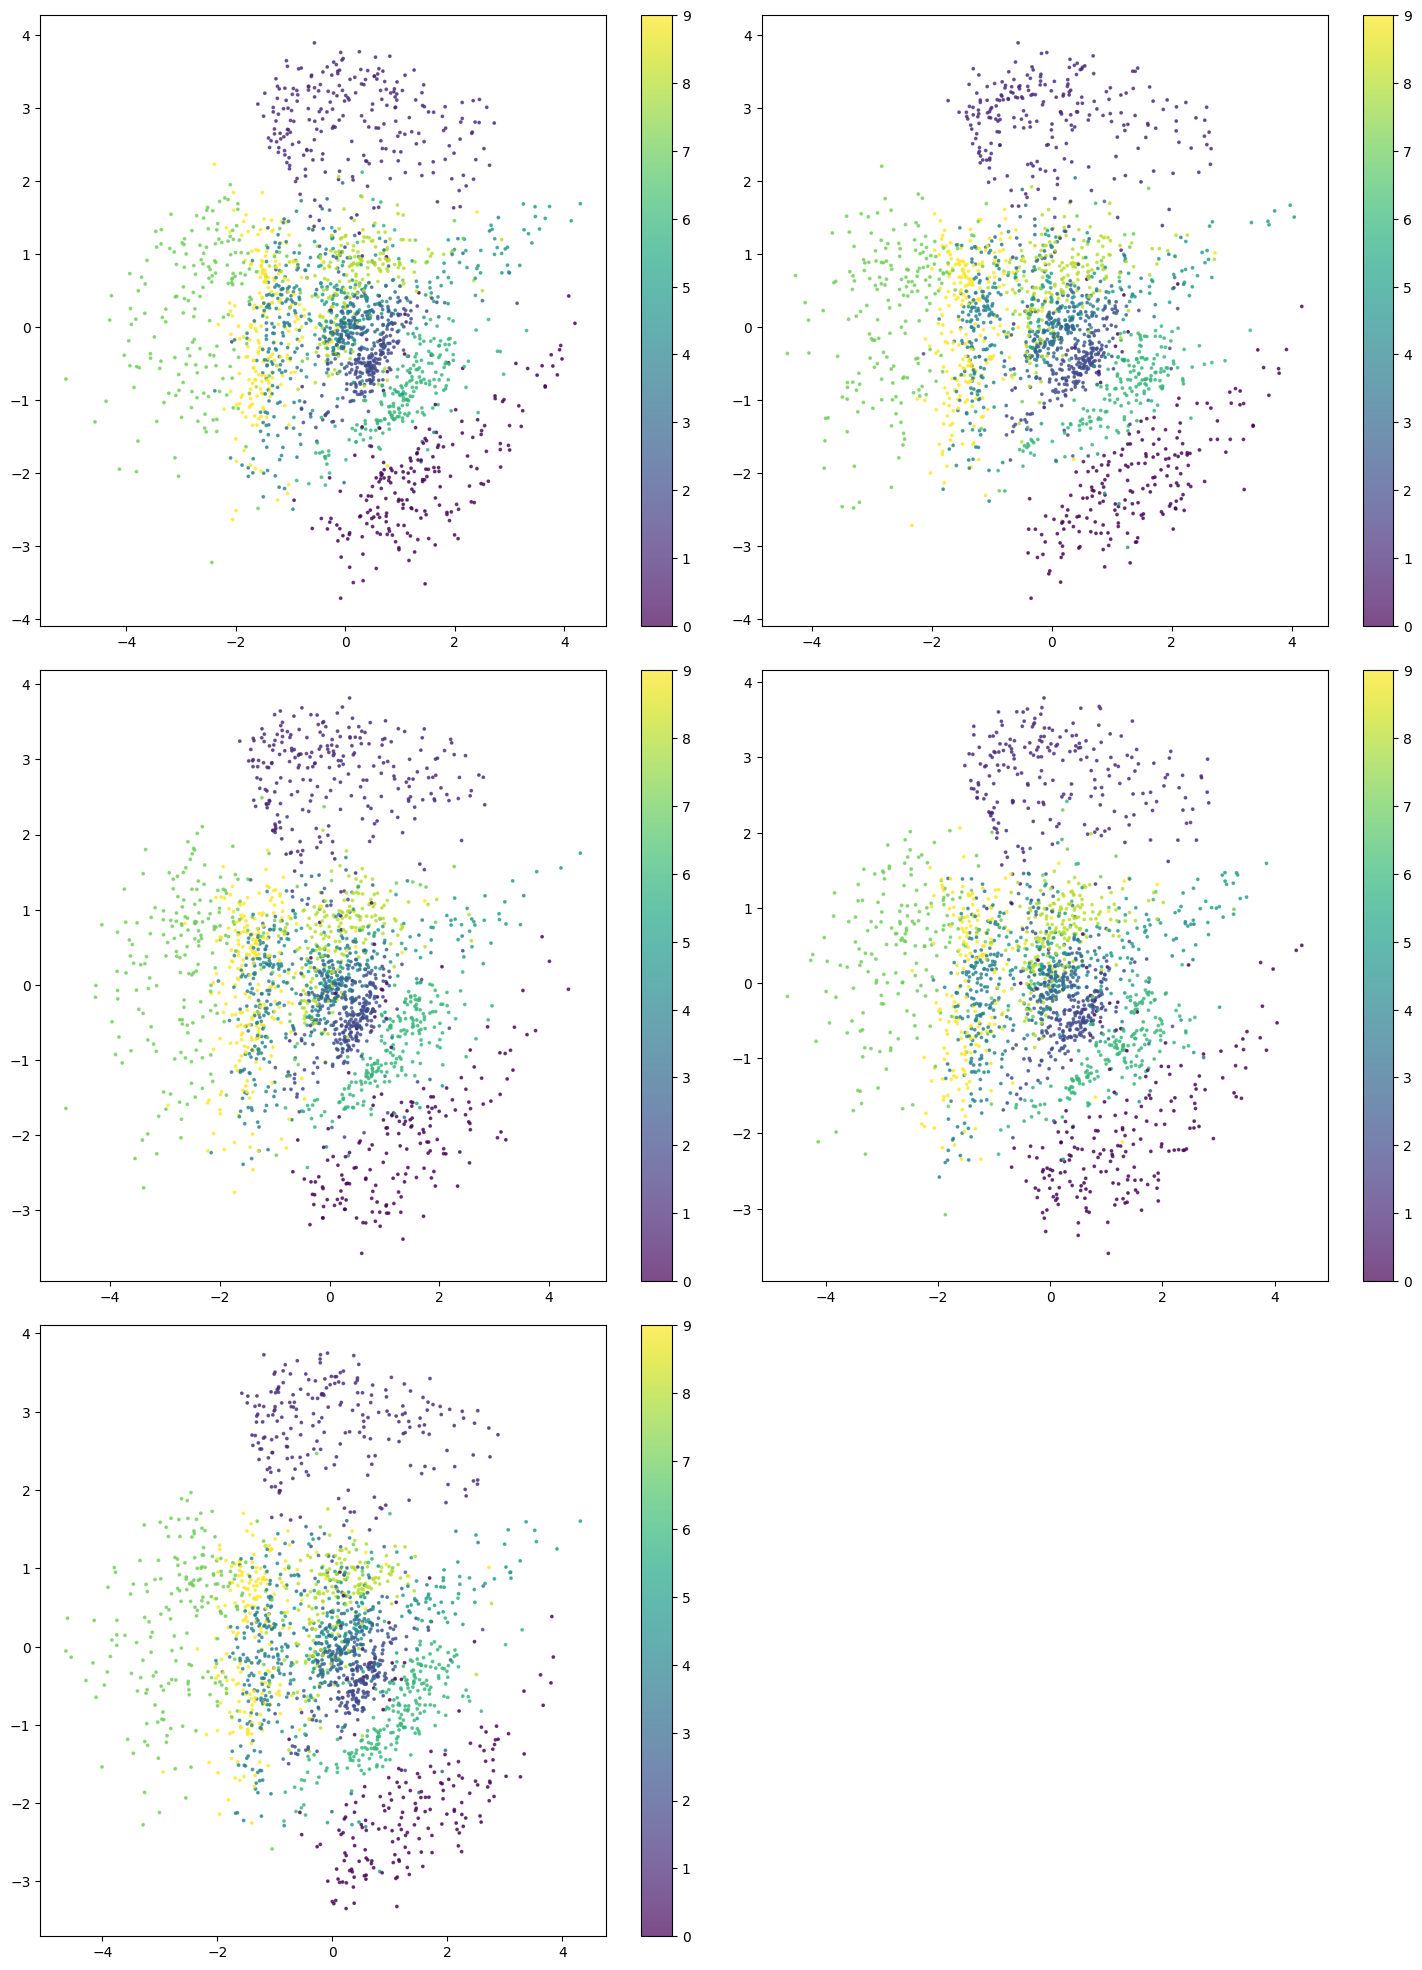

In [ ]:
figure, axes = plt.subplots(3,2, figsize=(15, 20))
axes = axes.flatten()

for i, result in enumerate(results):
    sample_size = 2000
    indices = np.random.choice(len(x_train), sample_size, replace=False)
    x_sample = x_train[indices]
    
    y_sample = y_train[indices]
    
    z_mean, _, _ = encoder.predict(x_sample)
    
    scatter = axes[i].scatter(z_mean[:, 0], z_mean[:, 1], c=y_sample, cmap='viridis', alpha=0.7, s=3)

    plt.colorbar(scatter, ticks=range(10))
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.tight_layout()
    
figure.delaxes(axes[5])